In [3]:
import utils
import random
import matplotlib.pyplot as plt
import numpy as np

audio_paths = [
    # "../music-clips/classical_8.wav",
    "../music-clips/classical_1.wav",
    "../music-clips/classical_2.wav",
    # "../music-clips/classical_6.wav",
    "../music-clips/electronic_1.wav",
    # "../music-clips/electronic_10.wav",
    # "../music-clips/electronic_14.wav",
    "../music-clips/electronic_3.wav",
]
model, processor = utils.load_music_gen_model()
wfs = utils.load_process_bulk_audio(audio_paths, sr=32000)
inputs_dict = utils.process_bulk_music_gen(wfs, processor=processor)


attentions_dict_clean = utils.extract_attentions(model, inputs_dict, chunk_size=None)
attentions_dict_shuffled = utils.extract_attentions(model, inputs_dict, chunk_size=1)

Loading weights:   0%|          | 0/611 [00:00<?, ?it/s]

In [4]:
# print(attentions_dict_clean)

mad_dict_clean = utils.compute_mad_dict(attentions_dict_clean)
mad_dict_shuffled = utils.compute_mad_dict(attentions_dict_shuffled)

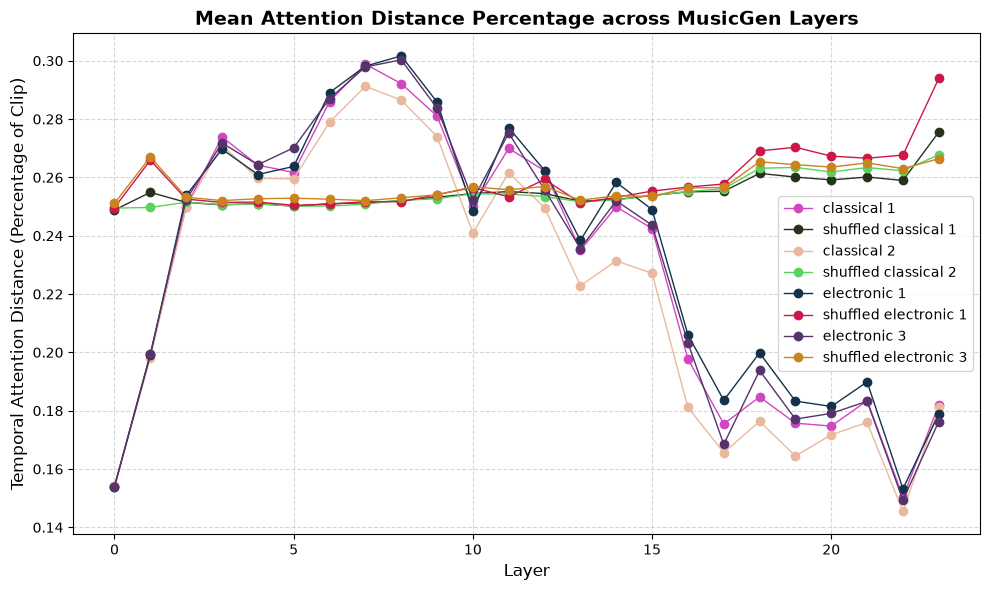

In [11]:
plt.figure(figsize=(10, 6))

for path, mads in mad_dict_clean.items():
    random_hex = f"#{random.randint(0, 0xFFFFFF):06x}"
    num_layers = len(attentions_dict_clean.get(path))
    layer_averages_clean = np.mean(mads, axis=1)
    layer_averages_shuffled = np.mean(mad_dict_shuffled.get(path), axis=1)
    plt.plot(range(num_layers), layer_averages_clean, color=random_hex, linewidth=1, marker='o', label=path.replace("../music-clips/", "").replace(".wav", "").replace("_", " "))
    plt.plot(range(num_layers), layer_averages_shuffled, color=f"#{random.randint(0, 0xFFFFFF):06x}", linewidth=1, marker='o', label='shuffled ' + path.replace("../music-clips/", "").replace(".wav", "").replace("_", " "))

plt.title("Mean Attention Distance Percentage across MusicGen Layers", fontsize=14, fontweight='bold')
plt.xlabel("Layer", fontsize=12)
plt.ylabel("Temporal Attention Distance (Percentage of Clip)", fontsize=12)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend()
plt.tight_layout()